## Prepare Environment

In [2]:
# Set up MongoDB Connection via MongoDB Compass

from pymongo import MongoClient

# MongoDB connection to MongoDBCompass 
client = MongoClient("mongodb://localhost:27017/")

# Select the database
db = client['mydatabase']

# Select or create a collection
collection = db['mycollection']

# Insert a document into the collection
document = {"name": "John", "age": 30, "city": "New York"}
collection.insert_one(document)

# Fetch documents from the collection
for doc in collection.find():
    print(doc)


KeyboardInterrupt: 

In [1]:
import getpass
from langchain_openai import ChatOpenAI
from ai_core.utils import os, logging
from ai_core.workflow_generator import create_new_workflow

debug = False

def _set_if_undefined(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"Please provide your {var}")


_set_if_undefined("OPENAI_API_KEY")
_set_if_undefined("TAVILY_API_KEY")
_set_if_undefined("LANGCHAIN_API_KEY")

os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_PROJECT"] = "caipo workflow"

llm = ChatOpenAI(model="gpt-4o")


for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)

if debug:
    logging_level = logging.INFO
else:
    logging_level = logging.ERROR
logging.basicConfig(level=logging_level, format='%(asctime)s - %(levelname)s - %(message)s')

## Set Objective of Workflow To Be Created

In [6]:
obj = 'build a travel plan'

## Create Workflow

In [7]:
from tools.tool_factory import get_all_tools

workflow = create_new_workflow(llm, obj, get_all_tools(), debug=debug)

## View Workflow visually

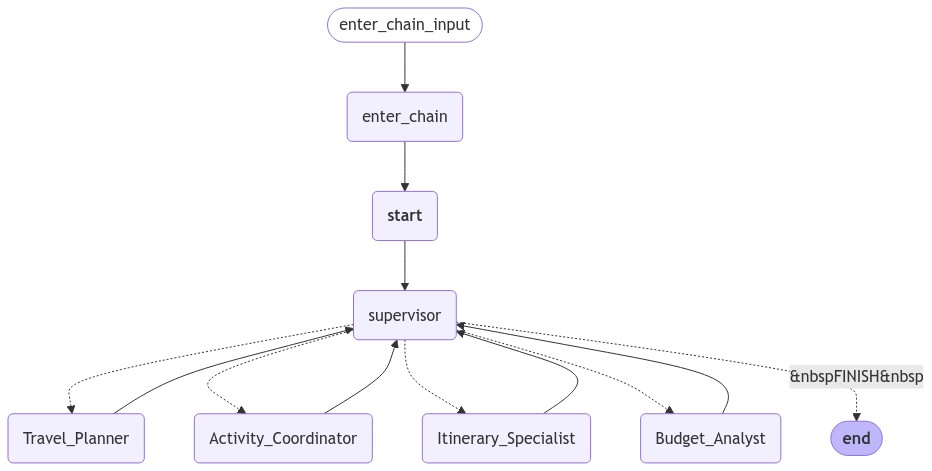

In [8]:
from IPython.display import Image, display

display(Image(workflow.get_graph().draw_mermaid_png()))

## Call Workflow to do work

In [9]:
response = workflow.invoke("post an instance about a trip to europe")

In [10]:
for msg in response['messages']:
    print(msg.content)

post an instance about a trip to europe
```json
{
  "destination_name": "Maribor, Slovenia",
  "destination_description": "Maribor is a charming cultural, culinary, and educational centre in the north-eastern part of Slovenia. The city's deep cultural and historical roots date back to the Middle Ages, and the old city centre offers a rich heritage and a wealth of genuine experiences.",
  "popularity_score": 8.5,
  "recommended_activities": [
    "Explore the old city centre",
    "Visit the Maribor Castle",
    "Enjoy local Slovenian cuisine",
    "Attend cultural festivals and events"
  ]
}
```
```json
{
  "activity_name": "Explore the Old Vine House",
  "activity_description": "Taste the world’s oldest vine and explore Maribor’s rich wine heritage at the Old Vine House. It offers a unique glimpse into the historical and cultural significance of winemaking in the region.",
  "activity_location": "Old Vine House, Lent, Maribor",
  "activity_cost": 10,
  "activity_duration": "2 hours"
}

## Delete Workflow

In [ ]:
from ai_core.utils import delete_workflow

delete_workflow(obj)